In [11]:
# ============================================
# NIGERIAFLOODWATCH
# Task 3.4: Local Lokoja Floodplain Analysis
# ============================================

from pathlib import Path
import zipfile
import warnings

import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt

from shapely.geometry import Polygon, MultiPolygon
from shapely.validation import explain_validity

import os

os.environ["SHAPE_RESTORE_SHX"] = "YES"

warnings.filterwarnings("ignore", category=UserWarning)

# Project root
PROJECT_ROOT = Path("/workspaces/nigeria-flood-watch") 

# Source data directory
RAW_DIR = PROJECT_ROOT / "data" / "raw"

# Processed data directory
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"

# Create processed directory if it does not exist
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

# Source archives
COPERNICUS_ZIP = (
        RAW_DIR /
            "EMSR314_02LOKOJA_01DELINEATION_MAP_v1_vector.zip"
)

LOKOJA_LGA_ZIP = (
        RAW_DIR /
            "lokoja_lga_utm32n.zip"
)

print("Project root:", PROJECT_ROOT)
print("Raw directory:", RAW_DIR)
print("Processed directory:", PROCESSED_DIR)

print("\nCopernicus archive exists:", COPERNICUS_ZIP.exists())
print("Lokoja LGA archive exists:", LOKOJA_LGA_ZIP.exists())


Project root: /workspaces/nigeria-flood-watch
Raw directory: /workspaces/nigeria-flood-watch/data/raw
Processed directory: /workspaces/nigeria-flood-watch/data/processed

Copernicus archive exists: True
Lokoja LGA archive exists: True


Inspecting the corpernicus archive

In [12]:
if not COPERNICUS_ZIP.exists():
    raise FileNotFoundError(
        f"Copernicus archive not found: {COPERNICUS_ZIP}"
    )

with zipfile.ZipFile(COPERNICUS_ZIP, "r") as archive:

    archive_contents = archive.namelist()

    print("Total files in archive:", len(archive_contents))
    print("\nARCHIVE CONTENTS:\n")

    for filename in archive_contents:
        print(filename)

Total files in archive: 52

ARCHIVE CONTENTS:

EMSR314_02LOKOJA_DEL_v1_area_of_interest_a.dbf
EMSR314_02LOKOJA_DEL_v1_area_of_interest_a.kmz
EMSR314_02LOKOJA_DEL_v1_area_of_interest_a.prj
EMSR314_02LOKOJA_DEL_v1_area_of_interest_a.shp
EMSR314_02LOKOJA_DEL_v1_area_of_interest_a.shx
EMSR314_02LOKOJA_DEL_v1_built_up_a.dbf
EMSR314_02LOKOJA_DEL_v1_built_up_a.kmz
EMSR314_02LOKOJA_DEL_v1_built_up_a.prj
EMSR314_02LOKOJA_DEL_v1_built_up_a.shp
EMSR314_02LOKOJA_DEL_v1_built_up_a.shx
EMSR314_02LOKOJA_DEL_v1_facilities_p.dbf
EMSR314_02LOKOJA_DEL_v1_facilities_p.kmz
EMSR314_02LOKOJA_DEL_v1_facilities_p.prj
EMSR314_02LOKOJA_DEL_v1_facilities_p.shp
EMSR314_02LOKOJA_DEL_v1_facilities_p.shx
EMSR314_02LOKOJA_DEL_v1_hydrography_a.dbf
EMSR314_02LOKOJA_DEL_v1_hydrography_a.kmz
EMSR314_02LOKOJA_DEL_v1_hydrography_a.prj
EMSR314_02LOKOJA_DEL_v1_hydrography_a.shp
EMSR314_02LOKOJA_DEL_v1_hydrography_a.shx
EMSR314_02LOKOJA_DEL_v1_hydrography_l.dbf
EMSR314_02LOKOJA_DEL_v1_hydrography_l.kmz
EMSR314_02LOKOJA_DEL_v1_

In [13]:
# Identify relevant shapefile components

keywords = [
    "observed_event_a",
    "area_of_interest_a",
    "hydrography_a",
    "hydrography_l",
    "built_up_a",
    "transportation_l",
    "physiography_l"
]

print("\nRELEVANT FILES:\n")

for filename in archive_contents:
    if any(keyword.lower() in filename.lower() for keyword in keywords):
        print(filename)


RELEVANT FILES:

EMSR314_02LOKOJA_DEL_v1_area_of_interest_a.dbf
EMSR314_02LOKOJA_DEL_v1_area_of_interest_a.kmz
EMSR314_02LOKOJA_DEL_v1_area_of_interest_a.prj
EMSR314_02LOKOJA_DEL_v1_area_of_interest_a.shp
EMSR314_02LOKOJA_DEL_v1_area_of_interest_a.shx
EMSR314_02LOKOJA_DEL_v1_built_up_a.dbf
EMSR314_02LOKOJA_DEL_v1_built_up_a.kmz
EMSR314_02LOKOJA_DEL_v1_built_up_a.prj
EMSR314_02LOKOJA_DEL_v1_built_up_a.shp
EMSR314_02LOKOJA_DEL_v1_built_up_a.shx
EMSR314_02LOKOJA_DEL_v1_hydrography_a.dbf
EMSR314_02LOKOJA_DEL_v1_hydrography_a.kmz
EMSR314_02LOKOJA_DEL_v1_hydrography_a.prj
EMSR314_02LOKOJA_DEL_v1_hydrography_a.shp
EMSR314_02LOKOJA_DEL_v1_hydrography_a.shx
EMSR314_02LOKOJA_DEL_v1_hydrography_l.dbf
EMSR314_02LOKOJA_DEL_v1_hydrography_l.kmz
EMSR314_02LOKOJA_DEL_v1_hydrography_l.prj
EMSR314_02LOKOJA_DEL_v1_hydrography_l.shp
EMSR314_02LOKOJA_DEL_v1_hydrography_l.shx
EMSR314_02LOKOJA_DEL_v1_observed_event_a.dbf
EMSR314_02LOKOJA_DEL_v1_observed_event_a.kmz
EMSR314_02LOKOJA_DEL_v1_observed_event_a.p

loading and inspecting the flood polygons

In [16]:
from pathlib import Path
import zipfile

EXTRACT_DIR = RAW_DIR / "EMSR314_02_extracted"

EXTRACT_DIR.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(COPERNICUS_ZIP, "r") as archive:
    archive.extractall(EXTRACT_DIR)

print("Extraction completed.")
print("Extraction directory:", EXTRACT_DIR)

Extraction completed.
Extraction directory: /workspaces/nigeria-flood-watch/data/raw/EMSR314_02_extracted


In [17]:
flood_shapefiles = list(
    EXTRACT_DIR.rglob("EMSR314_02LOKOJA_DEL_v1_observed_event_a.shp")
)

if len(flood_shapefiles) != 1:
    raise FileNotFoundError(
        f"Expected one observed flood shapefile, found: {len(flood_shapefiles)}"
    )

flood_shapefile = flood_shapefiles[0]

print("Observed flood shapefile:", flood_shapefile)

print("\nSupporting files:")

for extension in [".shp", ".shx", ".dbf", ".prj"]:
    matches = list(
        flood_shapefile.parent.glob(f"{flood_shapefile.stem}{extension}")
    )
    print(extension, ":", bool(matches))

Observed flood shapefile: /workspaces/nigeria-flood-watch/data/raw/EMSR314_02_extracted/EMSR314_02LOKOJA_DEL_v1_observed_event_a.shp

Supporting files:
.shp : True
.shx : True
.dbf : True
.prj : True


In [ ]:
# Allow GDAL to reconstruct missing SHX files in the writable directory
os.environ["SHAPE_RESTORE_SHX"] = "YES"

flood_gdf = gpd.read_file(flood_shapefile)

print("Flood layer loaded successfully.")

print("\nFeature count:", len(flood_gdf))
print("CRS:", flood_gdf.crs)

print("\nGeometry types:")
print(flood_gdf.geom_type.value_counts())

print("\nColumns:")
print(flood_gdf.columns.tolist())

print("\nBounding box:")
print(flood_gdf.total_bounds)

Flood layer loaded successfully.

Feature count: 1509
CRS: EPSG:4326

Geometry types:
Polygon         1496
MultiPolygon      13
Name: count, dtype: int64

Columns:
['event_type', 'obj_desc', 'det_method', 'notation', 'dmg_src_id', 'geometry']

Bounding box:
[6.70362823 7.7284658  7.00494625 7.97969175]


In [19]:
LGA_EXTRACT_DIR = RAW_DIR / "lokoja_lga_extracted"

LGA_EXTRACT_DIR.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(LOKOJA_LGA_ZIP, "r") as archive:
    archive.extractall(LGA_EXTRACT_DIR)

lga_shapefiles = list(LGA_EXTRACT_DIR.rglob("*.shp"))

if len(lga_shapefiles) != 1:
    raise ValueError(
        f"Expected one LGA shapefile, found: {len(lga_shapefiles)}"
    )

lokoja_lga = gpd.read_file(lga_shapefiles[0])

print("LOKOJA LGA LOADED")
print("Features:", len(lokoja_lga))
print("CRS:", lokoja_lga.crs)
print("Geometry:", lokoja_lga.geom_type.tolist())
print("Valid:", lokoja_lga.geometry.is_valid.all())

lokoja_lga_utm = lokoja_lga.to_crs("EPSG:32632")

print(
    "LGA area:",
    round(lokoja_lga_utm.geometry.area.sum() / 1_000_000, 4),
    "km²"
)

LOKOJA LGA LOADED
Features: 1
CRS: EPSG:32632
Geometry: ['Polygon']
Valid: True
LGA area: 3181.1678 km²


inspecting geometry validity and attributes

In [21]:


# Geometry validity
flood_gdf["geometry_valid"] = flood_gdf.geometry.is_valid

validity_summary = (
    flood_gdf["geometry_valid"]
    .value_counts(dropna=False)
)

print("GEOMETRY VALIDITY")
print(validity_summary)

print("\nInvalid geometries:")
print((~flood_gdf["geometry_valid"]).sum())

# Geometry type summary
print("\nGEOMETRY TYPES")
print(flood_gdf.geom_type.value_counts())

# Null and empty geometry checks
print("\nNULL GEOMETRIES:")
print(flood_gdf.geometry.isna().sum())

print("\nEMPTY GEOMETRIES:")
print(flood_gdf.geometry.is_empty.sum())

# Attribute completeness
print("\nATTRIBUTE NULL COUNTS:")
print(flood_gdf.drop(columns="geometry").isna().sum())

# Unique attribute values
for column in flood_gdf.columns:
    if column != "geometry" and column != "geometry_valid":
        print(f"\n{column.upper()} — UNIQUE VALUES")
        print(flood_gdf[column].value_counts(dropna=False).head(20))

# Explain invalid geometry reasons
invalid_flood = flood_gdf.loc[~flood_gdf["geometry_valid"]].copy()

print("\nINVALID GEOMETRY REASONS:")

for index, geometry in invalid_flood.geometry.head(10).items():
    print(index, ":", explain_validity(geometry))

GEOMETRY VALIDITY
geometry_valid
True     1405
False     104
Name: count, dtype: int64

Invalid geometries:
104

GEOMETRY TYPES
Polygon         1496
MultiPolygon      13
Name: count, dtype: int64

NULL GEOMETRIES:
0

EMPTY GEOMETRIES:
0

ATTRIBUTE NULL COUNTS:
event_type        0
obj_desc          0
det_method        0
notation          0
dmg_src_id        0
geometry_valid    0
dtype: int64

EVENT_TYPE — UNIQUE VALUES
event_type
5-Flood    1509
Name: count, dtype: int64

OBJ_DESC — UNIQUE VALUES
obj_desc
Riverine flood    1509
Name: count, dtype: int64

DET_METHOD — UNIQUE VALUES
det_method
Semi-automatic extraction    1509
Name: count, dtype: int64

NOTATION — UNIQUE VALUES
notation
Flooded area    1509
Name: count, dtype: int64

DMG_SRC_ID — UNIQUE VALUES
dmg_src_id
2    1509
Name: count, dtype: int64

INVALID GEOMETRY REASONS:
18 : Ring Self-intersection[6.76511791400003 7.74529034700004]
53 : Ring Self-intersection[6.76880100600005 7.76505328300004]
68 : Ring Self-intersection[6.77

loading the lokoja lga boundary

In [23]:
import zipfile
from pathlib import Path
import os

os.environ["SHAPE_RESTORE_SHX"] = "YES"

LGA_EXTRACT_DIR = RAW_DIR / "lokoja_lga_extracted"
LGA_EXTRACT_DIR.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(LOKOJA_LGA_ZIP, "r") as archive:
    archive.extractall(LGA_EXTRACT_DIR)

print("Extraction complete.")

for path in LGA_EXTRACT_DIR.rglob("*"):
    if path.is_file():
        print(path.name, path.stat().st_size, "bytes")

Extraction complete.
lokoja_lga_utm32n.sbx 116 bytes
lokoja_lga_utm32n.prj 402 bytes
lokoja_lga_utm32n.dbf 1307 bytes
lokoja_lga_utm32n.sbn 132 bytes
lokoja_lga_utm32n.shp 3548 bytes
lokoja_lga_utm32n.shx 108 bytes
EMSR314_02LOKOJA_01DELINEATION_MAP_v1_vector.zip 6556177 bytes


In [24]:
lga_shapefiles = list(LGA_EXTRACT_DIR.rglob("*.shp"))

if len(lga_shapefiles) != 1:
    raise ValueError(
        f"Expected one shapefile, found {len(lga_shapefiles)}"
    )

lga_shapefile = lga_shapefiles[0]

print("Reading:", lga_shapefile)

lokoja_lga = gpd.read_file(lga_shapefile)

print("\nLOKOJA LGA LOADED")
print("Features:", len(lokoja_lga))
print("CRS:", lokoja_lga.crs)
print("Geometry types:", lokoja_lga.geom_type.value_counts())
print("Valid:", lokoja_lga.geometry.is_valid.all())
print("Null geometries:", lokoja_lga.geometry.isna().sum())
print("Empty geometries:", lokoja_lga.geometry.is_empty.sum())

lokoja_lga_utm = lokoja_lga.to_crs("EPSG:32632")

print(
    "Area:",
    round(lokoja_lga_utm.geometry.area.sum() / 1_000_000, 4),
    "km²"
)

Reading: /workspaces/nigeria-flood-watch/data/raw/lokoja_lga_extracted/lokoja_lga_utm32n.shp

LOKOJA LGA LOADED
Features: 1
CRS: EPSG:32632
Geometry types: Polygon    1
Name: count, dtype: int64
Valid: True
Null geometries: 0
Empty geometries: 0
Area: 3181.1678 km²


visualising inspection of both datasets

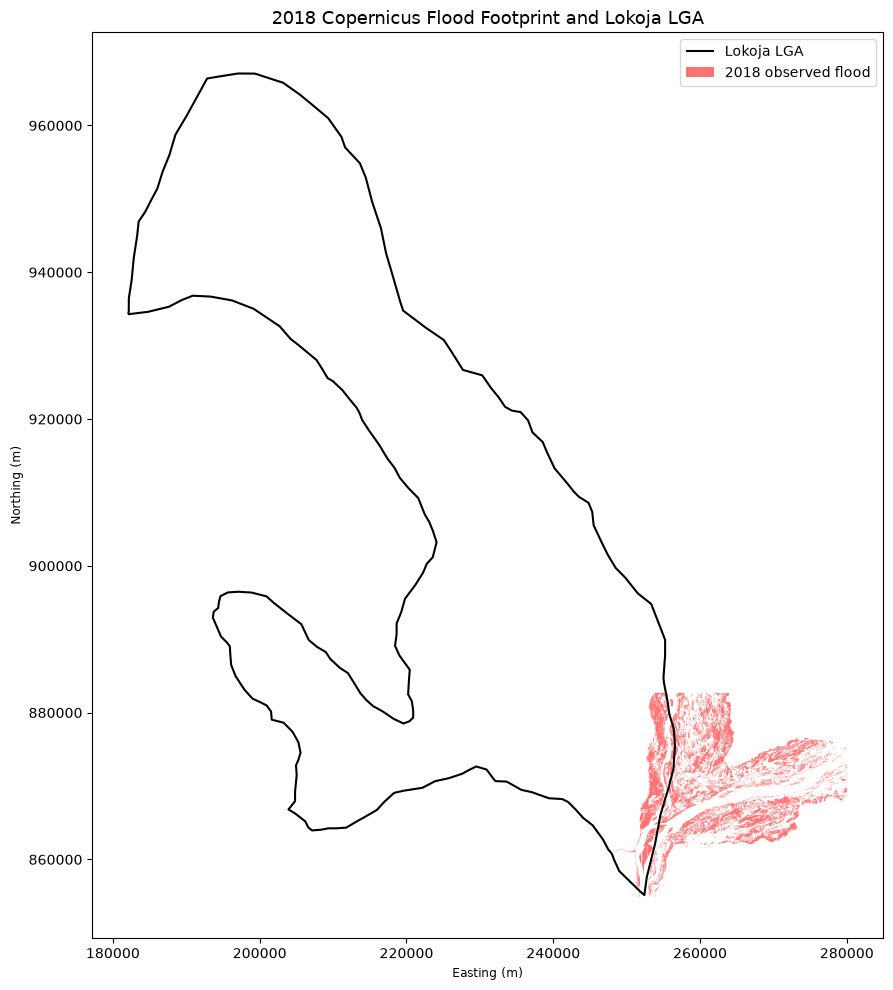

In [25]:
flood_utm = flood_gdf.to_crs("EPSG:32632")

fig, ax = plt.subplots(figsize=(10, 10))

lokoja_lga_utm.boundary.plot(
    ax=ax,
    color="black",
    linewidth=1.5,
    label="Lokoja LGA"
)

flood_utm.plot(
    ax=ax,
    color="red",
    alpha=0.55,
    edgecolor="none",
    label="2018 observed flood"
)

ax.set_title(
    "2018 Copernicus Flood Footprint and Lokoja LGA",
    fontsize=13
)

ax.set_xlabel("Easting (m)")
ax.set_ylabel("Northing (m)")

ax.legend()
ax.set_aspect("equal")

plt.tight_layout()
plt.show()